# Lab Sheet-09 · Project 2: Sales Data Analysis Dashboard
**MCA III Semester (Session 2026–2027) – Mini Projects on Data Analytics and Visualization**

**Objective:** build an interactive sales dashboard covering monthly sales, profit, customer segmentation, product performance and regional analysis.

In [22]:
# !pip install -q pandas numpy matplotlib seaborn plotly scikit-learn
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick
import seaborn as sns
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score
from sklearn.preprocessing import StandardScaler

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid")

## 1. Load data

In [23]:
df = pd.read_csv("C:\\Users\\HP\\\Desktop\labsheet mca\\Sample - Superstore.csv", encoding='latin1')
print(df.shape)
df.head()

(9994, 21)


,Row ID,Order ID,Order Date,Ship Date,Ship Mode,Customer ID,Customer Name,Segment,Country,City,...,Postal Code,Region,Product ID,Category,Sub-Category,Product Name,Sales,Quantity,Discount,Profit
0,1,CA-2016-152156,11/8/2016,11/11/2016,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,...,42420,South,FUR-BO-10001798,Furniture,Bookcases,Bush Somerset Collection Bookcase,261.9600,2,0.00,41.9136
1,2,CA-2016-152156,11/8/2016,11/11/2016,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,...,42420,South,FUR-CH-10000454,Furniture,Chairs,"Hon Deluxe Fabric Upholstered Stacking Chairs,...",731.9400,3,0.00,219.5820
2,3,CA-2016-138688,6/12/2016,6/16/2016,Second Class,DV-13045,Darrin Van Huff,Corporate,United States,Los Angeles,...,90036,West,OFF-LA-10000240,Office Supplies,Labels,Self-Adhesive Address Labels for Typewriters b...,14.6200,2,0.00,6.8714
3,4,US-2015-108966,10/11/2015,10/18/2015,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,...,33311,South,FUR-TA-10000577,Furniture,Tables,Bretford CR4500 Series Slim Rectangular Table,957.5775,5,0.45,-383.0310
4,5,US-2015-108966,10/11/2015,10/18/2015,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,...,33311,South,OFF-ST-10000760,Office Supplies,Storage,Eldon Fold 'N Roll Cart System,22.3680,2,0.20,2.5164


## 2. EDA

In [24]:
df.info()
display(df.describe().T.round(2))
display(df.describe(include="object").T)

<class 'pandas.DataFrame'>
RangeIndex: 9994 entries, 0 to 9993
Data columns (total 21 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Row ID         9994 non-null   int64  
 1   Order ID       9994 non-null   str    
 2   Order Date     9994 non-null   str    
 3   Ship Date      9994 non-null   str    
 4   Ship Mode      9994 non-null   str    
 5   Customer ID    9994 non-null   str    
 6   Customer Name  9994 non-null   str    
 7   Segment        9994 non-null   str    
 8   Country        9994 non-null   str    
 9   City           9994 non-null   str    
 10  State          9994 non-null   str    
 11  Postal Code    9994 non-null   int64  
 12  Region         9994 non-null   str    
 13  Product ID     9994 non-null   str    
 14  Category       9994 non-null   str    
 15  Sub-Category   9994 non-null   str    
 16  Product Name   9994 non-null   str    
 17  Sales          9994 non-null   float64
 18  Quantity       9994

,count,mean,std,min,25%,50%,75%,max
Row ID,9994.0,4997.50,2885.16,1.00,2499.25,4997.50,7495.75,9994.00
Postal Code,9994.0,55190.38,32063.69,1040.00,23223.00,56430.50,90008.00,99301.00
Sales,9994.0,229.86,623.25,0.44,17.28,54.49,209.94,22638.48
Quantity,9994.0,3.79,2.23,1.00,2.00,3.00,5.00,14.00
Discount,9994.0,0.16,0.21,0.00,0.00,0.20,0.20,0.80
Profit,9994.0,28.66,234.26,-6599.98,1.73,8.67,29.36,8399.98


,count,unique,top,freq
Order ID,9994,5009,CA-2017-100111,14
Order Date,9994,1237,9/5/2016,38
Ship Date,9994,1334,12/16/2015,35
Ship Mode,9994,4,Standard Class,5968
Customer ID,9994,793,WB-21850,37
Customer Name,9994,793,William Brown,37
Segment,9994,3,Consumer,5191
Country,9994,1,United States,9994
City,9994,531,New York City,915
State,9994,49,California,2001


## 3. Cleaning
Steps: parse dates → check missing values & duplicates → treat missing numeric by median / categorical by mode (or 'Unknown') → keep negative profit (genuine losses, not errors).

In [25]:
df["Order Date"] = pd.to_datetime(df["Order Date"])
df["Ship Date"] = pd.to_datetime(df["Ship Date"])
print("Missing values:\n", df.isna().sum()[df.isna().sum() > 0])
print("Duplicate rows:", df.duplicated().sum())
df = df.drop_duplicates()
for c in df.select_dtypes("number"):
    df[c] = df[c].fillna(df[c].median())
for c in df.select_dtypes("object"):
    df[c] = df[c].fillna("Unknown")
print("Missing after cleaning:", int(df.isna().sum().sum()))

Missing values:
 Series([], dtype: int64)
Duplicate rows: 0
Missing after cleaning: 0


## 4. Feature engineering

In [26]:
df["Year"] = df["Order Date"].dt.year
df["Month"] = df["Order Date"].dt.month
df["YearMonth"] = df["Order Date"].dt.to_period("M").dt.to_timestamp()
df["Ship Days"] = (df["Ship Date"] - df["Order Date"]).dt.days
df["Profit Margin %"] = df["Profit"] / df["Sales"] * 100

total_sales, total_profit = df["Sales"].sum(), df["Profit"].sum()
kpi = pd.Series({"Total Sales": total_sales, "Total Profit": total_profit,
                 "Profit margin %": total_profit / total_sales * 100, "Orders": df["Order ID"].nunique(),
                 "Customers": df["Customer ID"].nunique(), "Avg order value": total_sales / df["Order ID"].nunique()})
kpi.round(2)

Total Sales        2297200.86
Total Profit        286397.02
Profit margin %         12.47
Orders                5009.00
Customers              793.00
Avg order value        458.61
dtype: float64

## 5. Visual analysis

### 5.1 Monthly sales & profit – line + area (trend and seasonality)

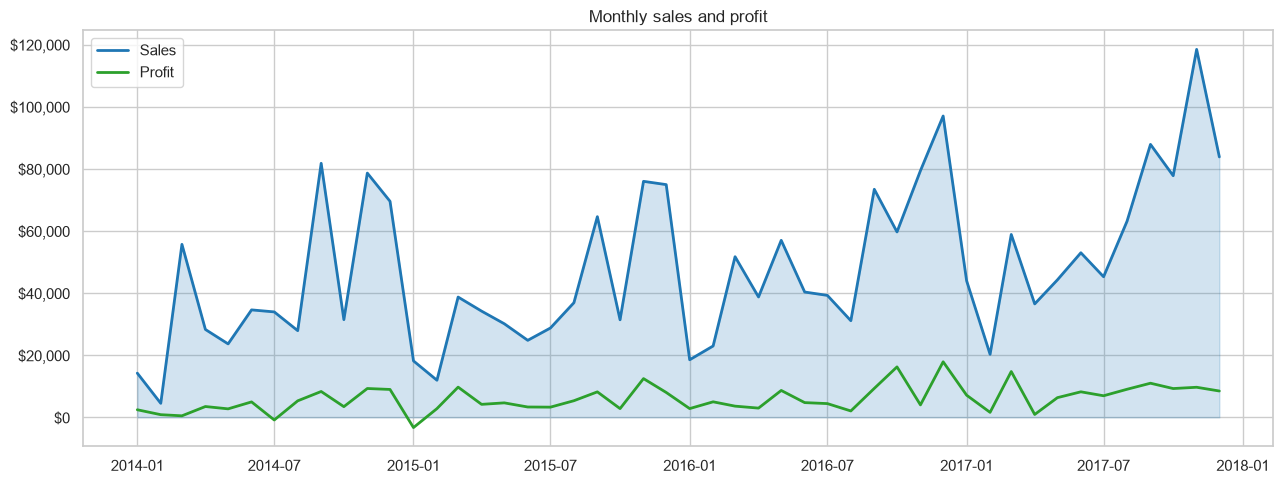

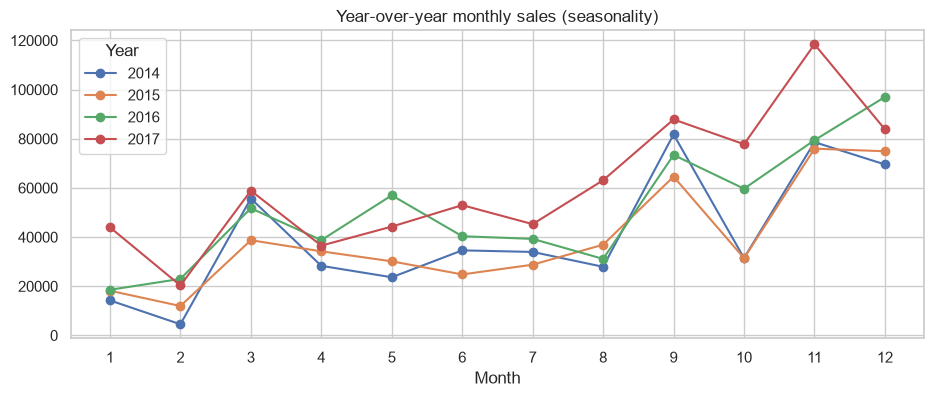

In [27]:
m = df.groupby("YearMonth")[["Sales", "Profit"]].sum()
fig, ax = plt.subplots(figsize=(13, 5))
ax.fill_between(m.index, m["Sales"], alpha=.2, color="#1f77b4"); ax.plot(m.index, m["Sales"], color="#1f77b4", label="Sales", lw=2)
ax.plot(m.index, m["Profit"], color="#2ca02c", label="Profit", lw=2)
ax.set_title("Monthly sales and profit"); ax.legend(); ax.yaxis.set_major_formatter(mtick.StrMethodFormatter("${x:,.0f}"))
plt.tight_layout(); plt.show()

pv = df.pivot_table(index="Month", columns="Year", values="Sales", aggfunc="sum")
pv.plot(figsize=(11, 4), marker="o", title="Year-over-year monthly sales (seasonality)"); plt.xticks(range(1, 13)); plt.show()

**Reading:** recurring peaks in the same months across years indicate seasonality (typically Sept–Dec); use it for inventory and campaign planning.

### 5.2 Product performance – category and sub-category

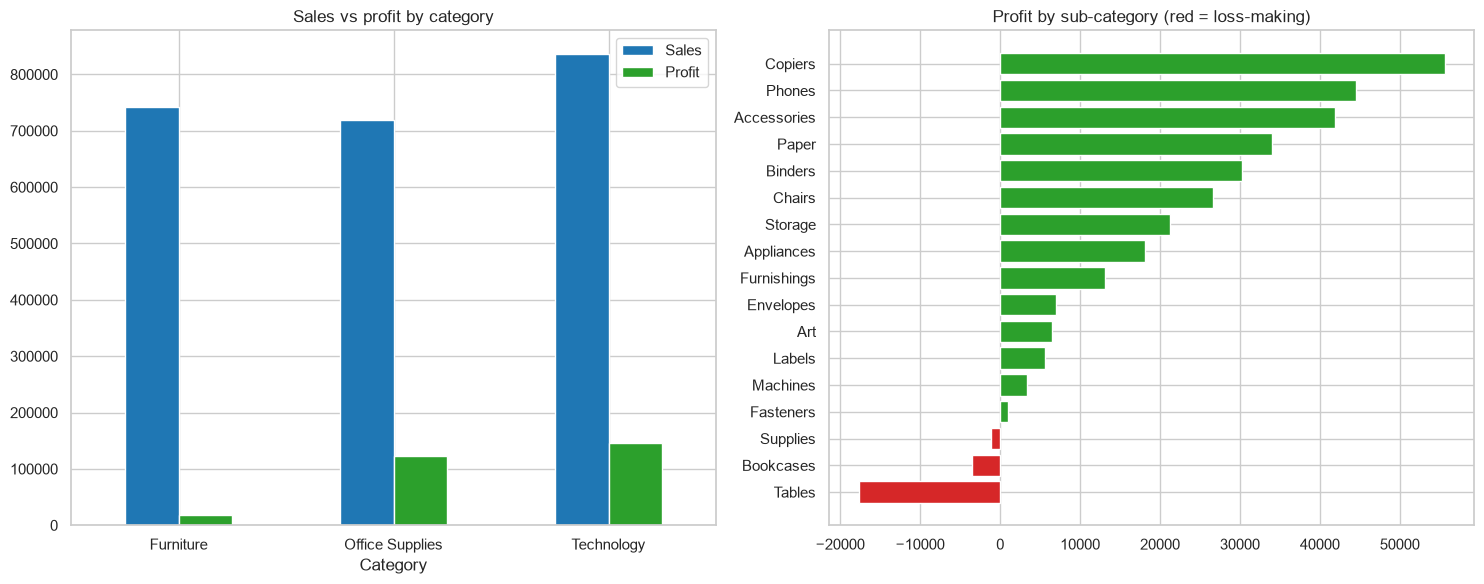

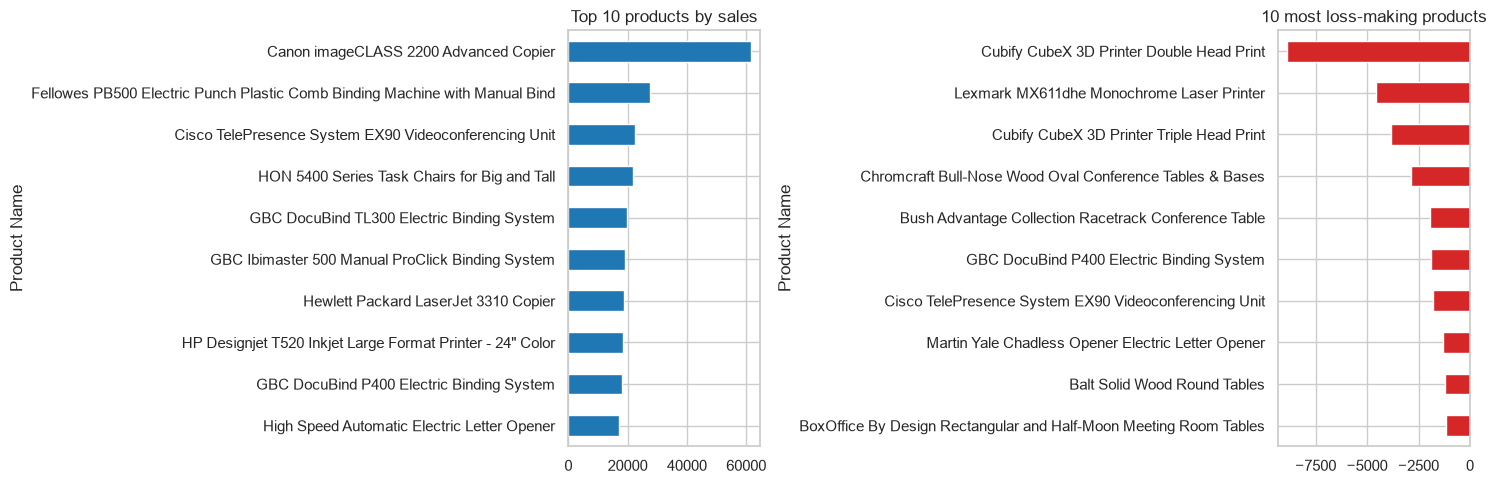

In [28]:
sub = df.groupby(["Category", "Sub-Category"])[["Sales", "Profit"]].sum().reset_index().sort_values("Profit")
fig, axes = plt.subplots(1, 2, figsize=(15, 6))
cat = df.groupby("Category")[["Sales", "Profit"]].sum()
cat.plot.bar(ax=axes[0], color=["#1f77b4", "#2ca02c"]); axes[0].set_title("Sales vs profit by category"); axes[0].tick_params(axis="x", rotation=0)
colors = np.where(sub["Profit"] < 0, "#d62728", "#2ca02c")
axes[1].barh(sub["Sub-Category"], sub["Profit"], color=colors); axes[1].set_title("Profit by sub-category (red = loss-making)")
plt.tight_layout(); plt.show()

prod = df.groupby("Product Name")[["Sales", "Profit"]].sum()
fig, axes = plt.subplots(1, 2, figsize=(15, 5))
prod["Sales"].nlargest(10).sort_values().plot.barh(ax=axes[0], color="#1f77b4", title="Top 10 products by sales")
prod["Profit"].nsmallest(10).sort_values(ascending=False).plot.barh(ax=axes[1], color="#d62728", title="10 most loss-making products")
plt.tight_layout(); plt.show()

### 5.3 Regional analysis

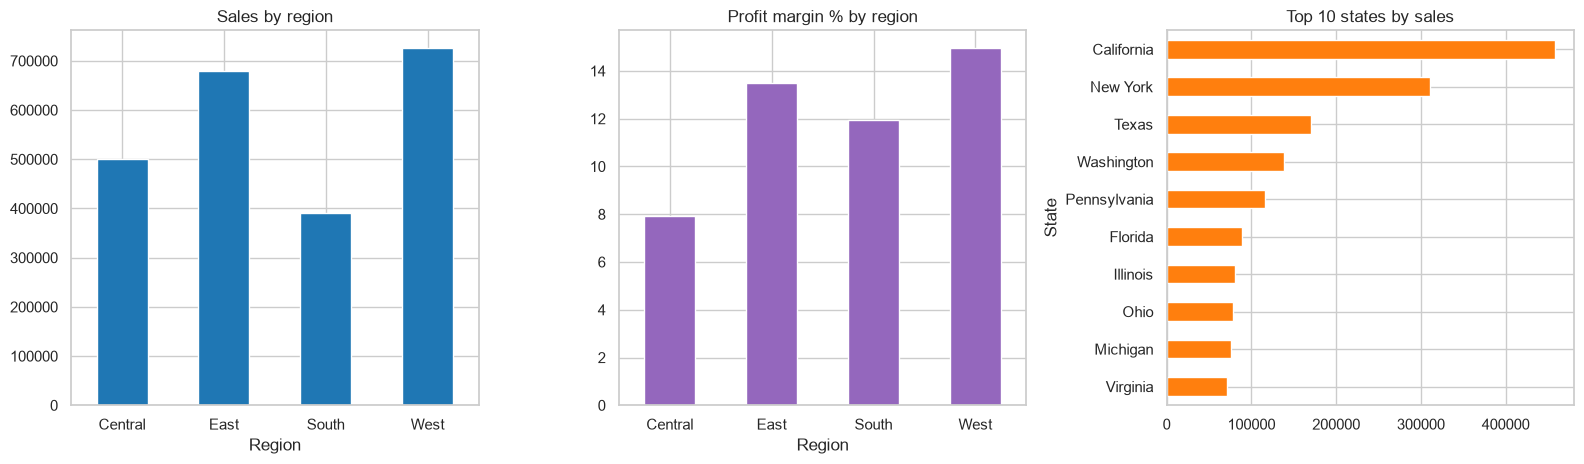

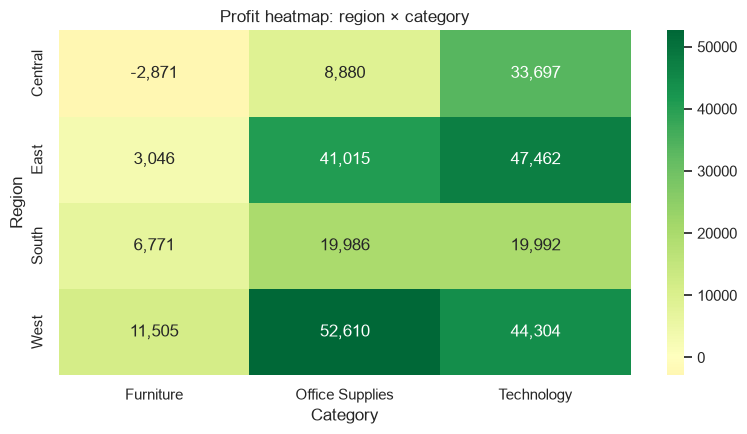

In [29]:
reg = df.groupby("Region")[["Sales", "Profit"]].sum()
reg["Margin %"] = reg["Profit"] / reg["Sales"] * 100
fig, axes = plt.subplots(1, 3, figsize=(16, 4.8))
reg["Sales"].plot.bar(ax=axes[0], color="#1f77b4", title="Sales by region"); axes[0].tick_params(axis="x", rotation=0)
reg["Margin %"].plot.bar(ax=axes[1], color="#9467bd", title="Profit margin % by region"); axes[1].tick_params(axis="x", rotation=0)
st = df.groupby("State")["Sales"].sum().nlargest(10).sort_values()
st.plot.barh(ax=axes[2], color="#ff7f0e", title="Top 10 states by sales")
plt.tight_layout(); plt.show()

plt.figure(figsize=(8, 4.5))
sns.heatmap(df.pivot_table(index="Region", columns="Category", values="Profit", aggfunc="sum"), annot=True, fmt=",.0f", cmap="RdYlGn", center=0)
plt.title("Profit heatmap: region × category"); plt.tight_layout(); plt.show()

### 5.4 Segments, shipping and the discount effect

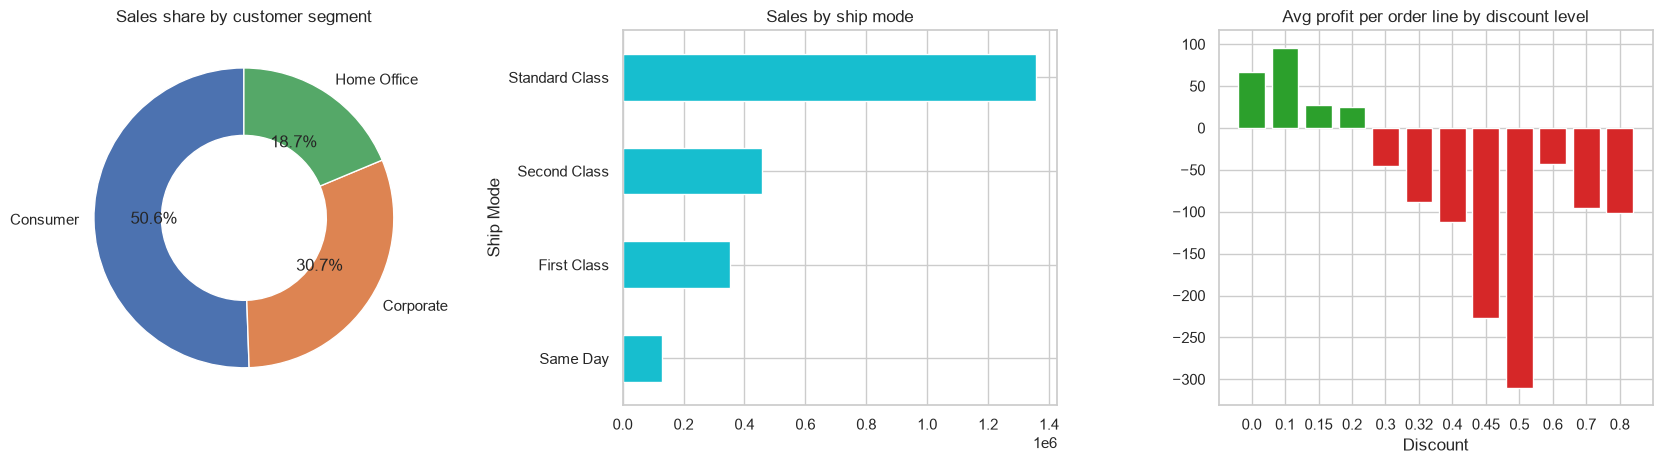

In [30]:
fig, axes = plt.subplots(1, 3, figsize=(17, 4.8))
seg = df.groupby("Segment")["Sales"].sum()
axes[0].pie(seg, labels=seg.index, autopct="%1.1f%%", startangle=90, wedgeprops=dict(width=.45)); axes[0].set_title("Sales share by customer segment")
df.groupby("Ship Mode")["Sales"].sum().sort_values().plot.barh(ax=axes[1], color="#17becf", title="Sales by ship mode")
dd = df.groupby("Discount")["Profit"].mean()
axes[2].bar(dd.index.astype(str), dd.values, color=np.where(dd.values < 0, "#d62728", "#2ca02c")); axes[2].set_title("Avg profit per order line by discount level")
axes[2].set_xlabel("Discount"); plt.tight_layout(); plt.show()

**Reading:** average profit typically turns negative beyond ~20–30 % discount – deep discounting destroys margin.

## 6. Customer segmentation – RFM + K-Means

RFM: **R**ecency (days since last purchase), **F**requency (number of orders), **M**onetary (total sales). Customers are clustered on standardized, log-transformed RFM values.

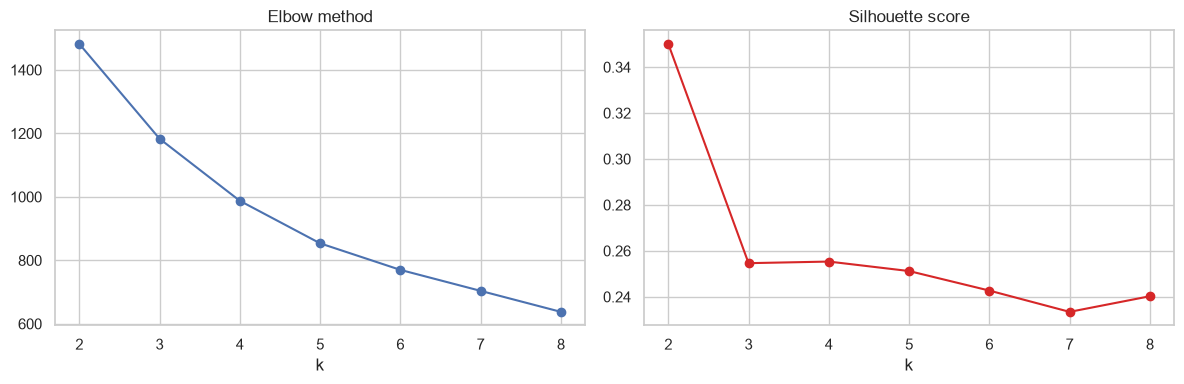

In [31]:
snap = df["Order Date"].max() + pd.Timedelta(days=1)
rfm = df.groupby("Customer ID").agg(Recency=("Order Date", lambda x: (snap - x.max()).days),
                                    Frequency=("Order ID", "nunique"), Monetary=("Sales", "sum"))
X = StandardScaler().fit_transform(np.log1p(rfm))

ks = range(2, 9)
inertia, sil = [], []
for k in ks:
    km = KMeans(k, n_init=10, random_state=42).fit(X)
    inertia.append(km.inertia_); sil.append(silhouette_score(X, km.labels_))
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(ks, inertia, "o-"); axes[0].set_title("Elbow method"); axes[0].set_xlabel("k")
axes[1].plot(ks, sil, "o-", color="#d62728"); axes[1].set_title("Silhouette score"); axes[1].set_xlabel("k")
plt.tight_layout(); plt.show()

,Customers,Recency,Frequency,Monetary
Cluster,,,,
Loyal,199,19.7,6.8,2712.9
Potential,253,235.2,4.9,1936.8
Champions,258,103.3,8.6,4773.0
At risk / Lost,83,326.6,2.6,432.2


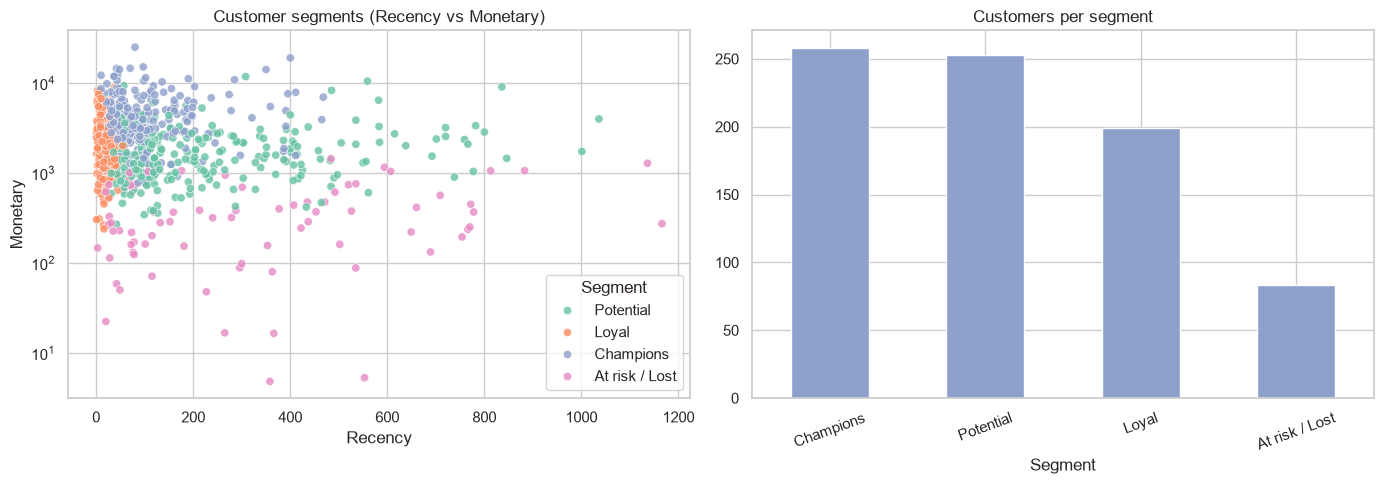

In [32]:
K = 4
rfm["Cluster"] = KMeans(K, n_init=10, random_state=42).fit_predict(X)
prof = rfm.groupby("Cluster").agg(Customers=("Recency", "size"), Recency=("Recency", "mean"),
                                  Frequency=("Frequency", "mean"), Monetary=("Monetary", "mean")).round(1)

# give business-friendly names: best monetary = Champions, highest recency (long ago) = At risk ...
names = {}
order = prof["Monetary"].sort_values(ascending=False).index
labels = ["Champions", "Loyal", "Potential", "At risk / Lost"]
for lab, cl in zip(labels, order):
    names[cl] = lab
rfm["Segment"] = rfm["Cluster"].map(names); prof.index = prof.index.map(names)
display(prof)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
sns.scatterplot(data=rfm, x="Recency", y="Monetary", hue="Segment", palette="Set2", ax=axes[0], alpha=.8); axes[0].set_yscale("log")
axes[0].set_title("Customer segments (Recency vs Monetary)")
rfm["Segment"].value_counts().plot.bar(ax=axes[1], color="#8da0cb", title="Customers per segment"); axes[1].tick_params(axis="x", rotation=20)
plt.tight_layout(); plt.show()

## 7. Interactive dashboard (Plotly)
Use the dropdown to filter by **region**; hover for exact values.

In [33]:
try:
    import plotly.graph_objects as go
    from plotly.subplots import make_subplots
    import plotly.express as px

    regions = ["All"] + sorted(df["Region"].unique())
    def monthly(r):
        d = df if r == "All" else df[df["Region"] == r]
        return d.groupby("YearMonth")[["Sales", "Profit"]].sum()

    fig = go.Figure()
    for i, r in enumerate(regions):
        mm = monthly(r)
        fig.add_trace(go.Scatter(x=mm.index, y=mm["Sales"], name="Sales", visible=(i == 0), line=dict(color="#1f77b4")))
        fig.add_trace(go.Scatter(x=mm.index, y=mm["Profit"], name="Profit", visible=(i == 0), line=dict(color="#2ca02c")))
    buttons = [dict(label=r, method="update",
                    args=[{"visible": [j // 2 == i for j in range(2 * len(regions))]}, {"title": f"Monthly sales & profit – {r}"}])
               for i, r in enumerate(regions)]
    fig.update_layout(updatemenus=[dict(buttons=buttons, x=0, y=1.18, xanchor="left")], title="Monthly sales & profit – All",
                      template="plotly_white", hovermode="x unified")
    fig.show()

    px.treemap(df, path=["Category", "Sub-Category"], values="Sales", color="Profit", color_continuous_scale="RdYlGn",
               color_continuous_midpoint=0, title="Sales (size) and profit (colour) by product").show()
    px.sunburst(df, path=["Region", "Segment", "Category"], values="Sales", title="Sales: region → segment → category").show()
except Exception as exc:
    print("Plotly not available:", exc)

Plotly not available: No module named 'plotly'


## 8. Static dashboard (export for screenshot)

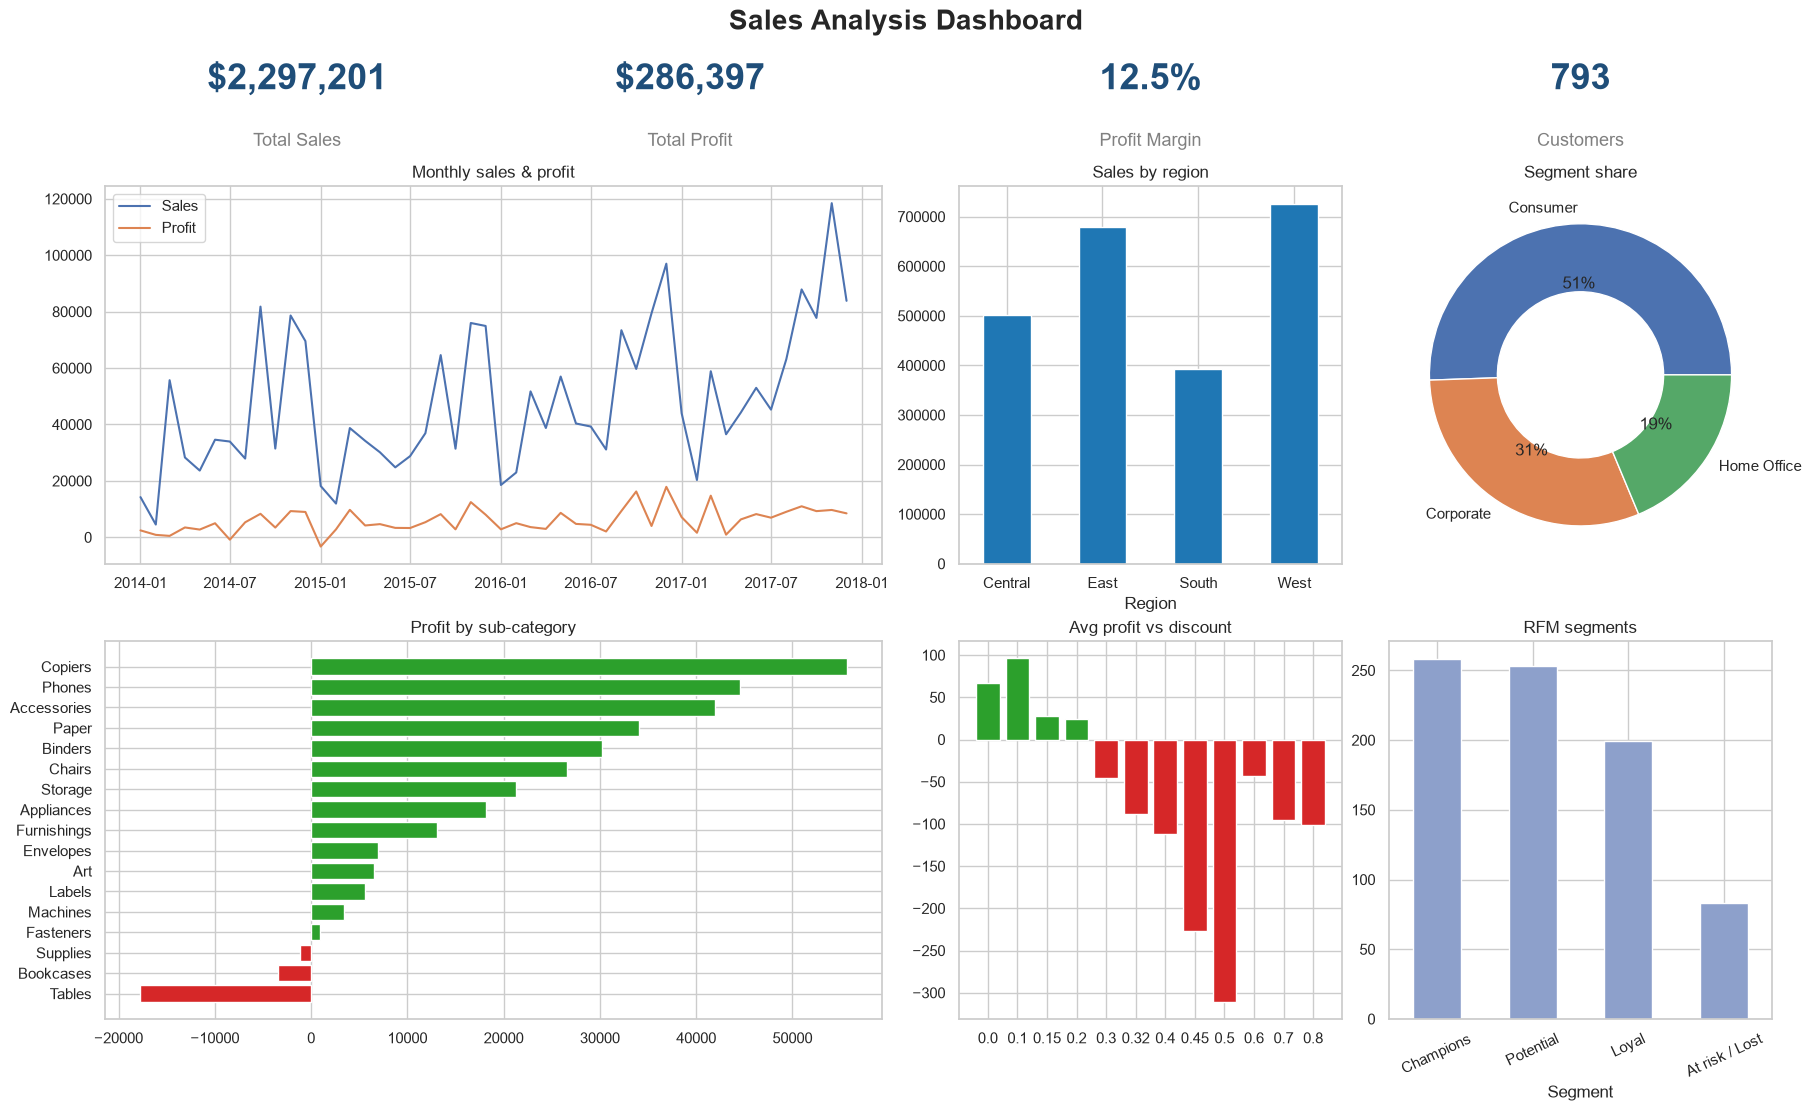

In [34]:
fig = plt.figure(figsize=(18, 11), constrained_layout=True)
gs = fig.add_gridspec(3, 4, height_ratios=[.3, 1, 1])
tiles = [("Total Sales", f"${total_sales:,.0f}"), ("Total Profit", f"${total_profit:,.0f}"),
         ("Profit Margin", f"{total_profit / total_sales * 100:.1f}%"), ("Customers", f"{df['Customer ID'].nunique():,}")]
for i, (n, v) in enumerate(tiles):
    ax = fig.add_subplot(gs[0, i]); ax.axis("off")
    ax.text(.5, .6, v, ha="center", fontsize=26, weight="bold", color="#1f4e79"); ax.text(.5, .1, n, ha="center", fontsize=13, color="gray")
ax = fig.add_subplot(gs[1, :2]); ax.plot(m.index, m["Sales"], label="Sales"); ax.plot(m.index, m["Profit"], label="Profit"); ax.legend(); ax.set_title("Monthly sales & profit")
ax = fig.add_subplot(gs[1, 2]); reg["Sales"].plot.bar(ax=ax, color="#1f77b4"); ax.set_title("Sales by region"); ax.tick_params(axis="x", rotation=0)
ax = fig.add_subplot(gs[1, 3]); ax.pie(seg, labels=seg.index, autopct="%1.0f%%", wedgeprops=dict(width=.45)); ax.set_title("Segment share")
ax = fig.add_subplot(gs[2, :2]); ax.barh(sub["Sub-Category"], sub["Profit"], color=colors); ax.set_title("Profit by sub-category")
ax = fig.add_subplot(gs[2, 2]); ax.bar(dd.index.astype(str), dd.values, color=np.where(dd.values < 0, "#d62728", "#2ca02c")); ax.set_title("Avg profit vs discount")
ax = fig.add_subplot(gs[2, 3]); rfm["Segment"].value_counts().plot.bar(ax=ax, color="#8da0cb"); ax.set_title("RFM segments"); ax.tick_params(axis="x", rotation=25)
fig.suptitle("Sales Analysis Dashboard", fontsize=20, weight="bold")
fig.savefig("sales_dashboard.png", dpi=130); plt.show()

## 9. Findings (computed)

In [35]:
best_m = m["Sales"].idxmax(); worst_sub = sub.iloc[0]; top_reg = reg["Sales"].idxmax()
print(f"""KEY INSIGHTS ({'Superstore data'})
1. Total sales ${total_sales:,.0f}, profit ${total_profit:,.0f} (margin {total_profit / total_sales * 100:.1f}%).
2. Strongest month: {best_m:%b %Y}. Seasonal peaks recur in the last quarter.
3. Top region by sales: {top_reg}; lowest margin region: {reg['Margin %'].idxmin()} ({reg['Margin %'].min():.1f}%).
4. Least profitable sub-category: {worst_sub['Sub-Category']} (${worst_sub['Profit']:,.0f}); most profitable: {sub.iloc[-1]['Sub-Category']}.
5. Discounts of {dd[dd < 0].index.min() if (dd < 0).any() else 'n/a'} and above lose money on average.
6. RFM: {prof['Customers'].get('Champions', 0)} 'Champions' generate the highest revenue; 'At risk' customers should get win-back offers.""")

KEY INSIGHTS (Superstore data)
1. Total sales $2,297,201, profit $286,397 (margin 12.5%).
2. Strongest month: Nov 2017. Seasonal peaks recur in the last quarter.
3. Top region by sales: West; lowest margin region: Central (7.9%).
4. Least profitable sub-category: Tables ($-17,725); most profitable: Copiers.
5. Discounts of 0.3 and above lose money on average.
6. RFM: 258 'Champions' generate the highest revenue; 'At risk' customers should get win-back offers.


### Business recommendations
1. Cap discounts (≈ ≤20 %) on loss-making sub-categories.
2. Stock up and run campaigns before the Q4 seasonal peak.
3. Investigate low-margin regions/states (pricing, shipping, returns).
4. Target RFM segments: reward *Champions*, nurture *Potential*, win back *At risk*.
